# Harmonic-weighted Gregory series: one trajectory for every $M$

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

$B(M)=\frac{\sqrt{M-1}}2\operatorname{Im}\operatorname{Li}_2(2/(1-i\sqrt{M-1}))$.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools.cmf.pfq import pFq
from cmfs import (
    gregory_target,
)

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
x0, x1, x2, y0, y1 = sp.symbols("x0 x1 x2 y0 y1")
half = sp.Rational(1, 2)


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. $M=2$: $B(2)=\tfrac12G+\tfrac\pi8\log2$

[Local manuscript](../overleaf_paper/New_directions_in_irrationality/main.tex).

**CMF:** dual ${}_3F_2(1/M)$; **start:** $(1/2,1/2,1/2;3/2,3/2)$.
**Direction:** $(2,2,2;3,3)$. **Readout:** $W_{00}/(W_{00}+4W_{10}+4W_{20})$.
N is the walk length; the dilogarithm target is evaluated independently.

In [5]:
cmf = pFq(3, 2, sp.Rational(1, 2)).dual()
start = {x0: half, x1: half, x2: half, y0: 3 * half, y1: 3 * half}
trajectory = {x0: 2, x1: 2, x2: 2, y0: 3, y1: 3}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[0, 0] / (W[0, 0] + 4 * W[1, 0] + 4 * W[2, 0]) for W in walks]
target = lambda: gregory_target(2)

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['$M=2$'] = (DEPTHS, deltas)
accuracy['$M=2$'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.567007415084


## 2. $M=4$: $B(4)=\tfrac98L(2,\chi_{-3})$

[Local manuscript](../overleaf_paper/New_directions_in_irrationality/main.tex).

**CMF:** dual ${}_3F_2(1/M)$; **start:** $(1/2,1/2,1/2;3/2,3/2)$.
**Direction:** $(2,2,2;3,3)$. **Readout:** $W_{00}/(W_{00}+4W_{10}+4W_{20})$.
N is the walk length; the dilogarithm target is evaluated independently.

In [7]:
cmf = pFq(3, 2, sp.Rational(1, 4)).dual()
start = {x0: half, x1: half, x2: half, y0: 3 * half, y1: 3 * half}
trajectory = {x0: 2, x1: 2, x2: 2, y0: 3, y1: 3}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[0, 0] / (W[0, 0] + 4 * W[1, 0] + 4 * W[2, 0]) for W in walks]
target = lambda: gregory_target(4)

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['$M=4$'] = (DEPTHS, deltas)
accuracy['$M=4$'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.288958593038


## 3. $M=7165$: the threshold of the CMF theorem

[Local manuscript](../overleaf_paper/New_directions_in_irrationality/main.tex).

**CMF:** dual ${}_3F_2(1/M)$; **start:** $(1/2,1/2,1/2;3/2,3/2)$.
**Direction:** $(2,2,2;3,3)$. **Readout:** $W_{00}/(W_{00}+4W_{10}+4W_{20})$.
N is the walk length; the dilogarithm target is evaluated independently.

In [9]:
cmf = pFq(3, 2, sp.Rational(1, 7165)).dual()
start = {x0: half, x1: half, x2: half, y0: 3 * half, y1: 3 * half}
trajectory = {x0: 2, x1: 2, x2: 2, y0: 3, y1: 3}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[0, 0] / (W[0, 0] + 4 * W[1, 0] + 4 * W[2, 0]) for W in walks]
target = lambda: gregory_target(7165)

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['$M=7165$'] = (DEPTHS, deltas)
accuracy['$M=7165$'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.004194532344


## 4. $M=10^6$

[Local manuscript](../overleaf_paper/New_directions_in_irrationality/main.tex).

**CMF:** dual ${}_3F_2(1/M)$; **start:** $(1/2,1/2,1/2;3/2,3/2)$.
**Direction:** $(2,2,2;3,3)$. **Readout:** $W_{00}/(W_{00}+4W_{10}+4W_{20})$.
N is the walk length; the dilogarithm target is evaluated independently.

In [11]:
cmf = pFq(3, 2, sp.Rational(1, 1000000)).dual()
start = {x0: half, x1: half, x2: half, y0: 3 * half, y1: 3 * half}
trajectory = {x0: 2, x1: 2, x2: 2, y0: 3, y1: 3}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[0, 0] / (W[0, 0] + 4 * W[1, 0] + 4 * W[2, 0]) for W in walks]
target = lambda: gregory_target(1000000)

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['$M=10^6$'] = (DEPTHS, deltas)
accuracy['$M=10^6$'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.198920783444


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

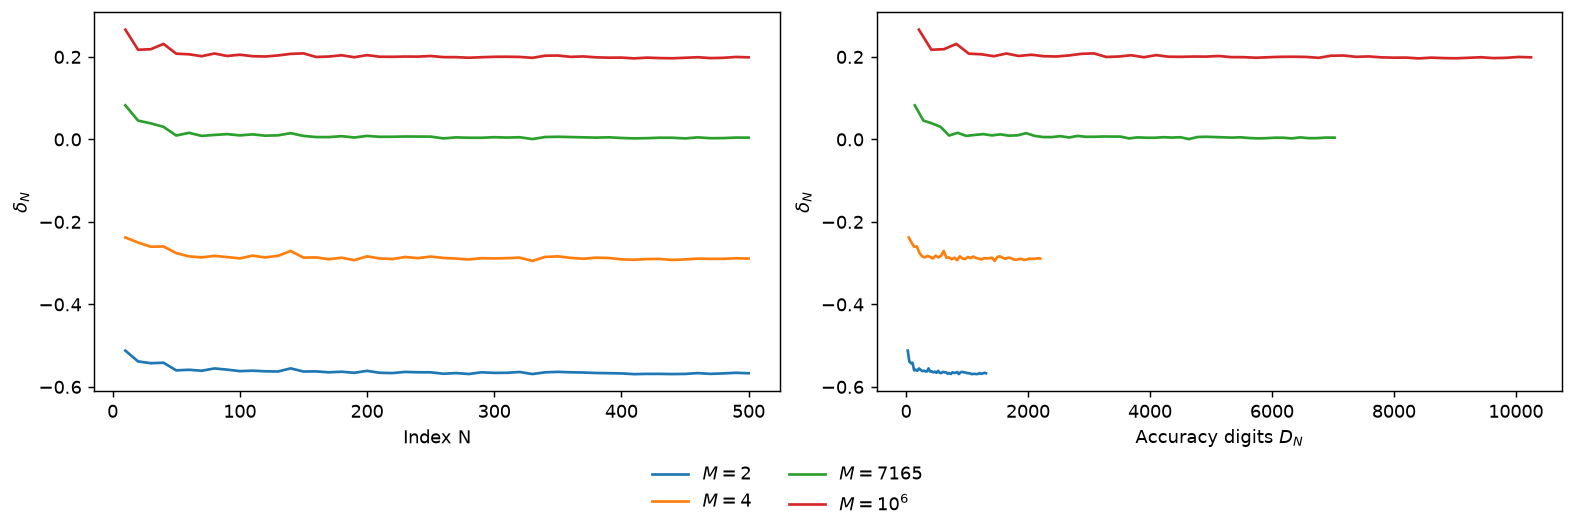

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [15]:
bounds = {
    '$M=2$': 'Approximation only',
    '$M=4$': 'Approximation only',
    '$M=7165$': 'CMF theorem under (H)',
    '$M=10^6$': 'CMF theorem under (H)',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| $M=2$ | Approximation only | -0.567007415084 (N = 500) |
| $M=4$ | Approximation only | -0.288958593038 (N = 500) |
| $M=7165$ | CMF theorem under (H) | 0.004194532344 (N = 500) |
| $M=10^6$ | CMF theorem under (H) | 0.198920783444 (N = 500) |